# DAT 301 Project 2
## Social Media and Mental Health Analysis
Jiyoo Lee

May 3, 2026

# 1. Background and Problem Definition

Social media became an inseparable part of our lives - from making and maintaining relationships, to getting information and following trends in various fields. It keeps people constantly connected with the world. However, there are also increasing concerns about the relationship between social media and mental health. Because social media is now a necessary part of our everyday social life, it is important to examine which specific factors - screen time, usage pattern, demographic information, etc. - are related to the negative influence of social media. This project focuses on the relationship between daily screen time and mental health outcomes, specifically anxiety (GAD-7) and depression (PHQ-9) scores. Furthermore, the analysis sought to investigate whether gender and activity type help explain variations in these relationships.

# 2. Dataset Preview
## 2 - 1. Dataset Structure and Variable Description

In this section, the data set is loaded, and its structure is examined. The dataset contains information about social media users, including their demographic information, usage patterns, and mental health scores.

In [9]:
# loading libraries and dataset
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('social_media_mental_health.csv')

# checking structure and variables
print('--- Data Information ---')
print(df.info())

# print first five rows
print('\n--- Variable Overview (first 5 rows) ---')
print(df.head(5))

--- Data Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   User_ID                    8000 non-null   object 
 1   Age                        8000 non-null   int64  
 2   Gender                     8000 non-null   object 
 3   User_Archetype             8000 non-null   object 
 4   Primary_Platform           8000 non-null   object 
 5   Daily_Screen_Time_Hours    8000 non-null   float64
 6   Dominant_Content_Type      8000 non-null   object 
 7   Activity_Type              8000 non-null   object 
 8   Late_Night_Usage           8000 non-null   int64  
 9   Social_Comparison_Trigger  8000 non-null   int64  
 10  Sleep_Duration_Hours       8000 non-null   float64
 11  GAD_7_Score                8000 non-null   int64  
 12  GAD_7_Severity             8000 non-null   object 
 13  PHQ_9_Score            

There are 15 variables in the dataset.

1. User ID: Unique identifier for each user
2. Age
3. Gender
4. User Archetype: User behavior classification (e.g., Hyper-Connected)
5. Primary Platform: Primary used social media platform
6. Daily Screen Time Hours: Average daily screen time in hours
7. Dominant Content Type: Main type of content consumed
8. Activity Type: Interaction style (Active vs. Passive)
9. Late Night Usage: Indicator for late-night usage(0 = No, 1 = Yes)
10. Social Comparison Trigger: Experience of social comparison triggers (0 = No, 1 = Yes)
11. Sleep Duration Hours: Average nightly sleep duration in hours
12. GAD-7 Score: Generalized Anxiety Disorder (GAD-7) score
13. GAD-7 Severity: Anxiety severity classification
14. PHQ-9 Score: Depression (PHQ-9) score
15. PHQ-9 Severity: Depression severity classification

## 2 - 2. Data Wrangling, Munging, and Cleaning

In this section, the dataset will be prepared in a more appropriate and convenient way for analysis. First, the total number of missing values will be checked and removed. Then, **lambda** is used to encode categorical variables (Gender and Activity Type) into numeric formats. Finally, the varibale names are shortened to create a 'final_df' for efficient analysis.

In [21]:
# Check and remove missing values (Data Cleaning)
print(f'Missing values per column:\n{df.isnull().sum()}')
df_clean = df.dropna().copy()
print(f'\nMissing values after cleaning: {len(df_clean)}')

# Encode data using Lambda (Data Munging)
## Gender: Female = 1, Male = 0
df_clean['gen_n'] = df_clean['Gender'].apply(lambda x: 1 if x == 'Female' else 0)

## Activity type: Active = 1, Passive = 0
df_clean['act_n'] = df_clean['Activity_Type'].apply(lambda x: 1 if x == 'Active' else 0)

# Rename variables for convenience
name_dict = {
    'Age': 'age',
    'Gender': 'gen',
    'Daily_Screen_Time_Hours': 'time',
    'Activity_Type': 'act',
    'GAD_7_Score': 'gad',
    'PHQ_9_Score': 'phq'
}

final_df = df_clean.rename(columns = name_dict)

# Create final dataframe for analysis (Data Wrangling)

final_df = final_df[['age', 'gen', 'gen_n', 'time', 'act', 'act_n', 'gad', 'phq']]

# Check dataset
print('\n--- Final Dataset Overview (first 5 rows) ---')
display(final_df.head())
print(f'\nTotal Rows: {len(final_df)}')
print(f'\nMising Values:\n{final_df.isnull().sum()}')

Missing values per column:
User_ID                      0
Age                          0
Gender                       0
User_Archetype               0
Primary_Platform             0
Daily_Screen_Time_Hours      0
Dominant_Content_Type        0
Activity_Type                0
Late_Night_Usage             0
Social_Comparison_Trigger    0
Sleep_Duration_Hours         0
GAD_7_Score                  0
GAD_7_Severity               0
PHQ_9_Score                  0
PHQ_9_Severity               0
dtype: int64

Missing values after cleaning: 8000

--- Final Dataset Overview (first 5 rows) ---


,age,gen,gen_n,time,act,act_n,gad,phq
0,18,Male,0,8.50,Active,1,9,5
1,20,Male,0,0.50,Active,1,0,8
2,18,Female,1,0.91,Active,1,1,3
3,18,Female,1,7.43,Active,1,13,0
4,18,Male,0,4.94,Active,1,13,10



Total Rows: 8000

Mising Values:
age      0
gen      0
gen_n    0
time     0
act      0
act_n    0
gad      0
phq      0
dtype: int64


# 3. Exploratory Data Analysis (EDA)

This secton examines the distributions of key variables - age, gender, screen time, activity type, GAD-7 score, and PHQ-9 score.

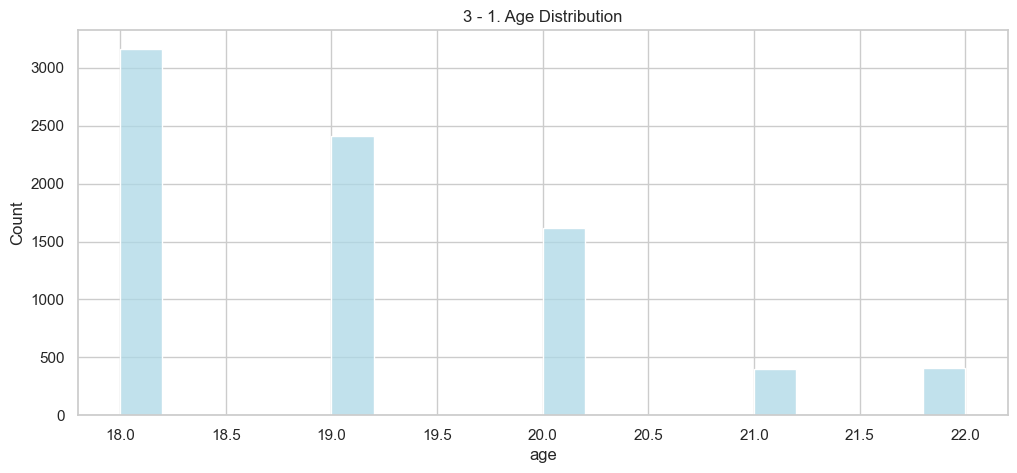

,Average,Min,Max
age,19.06,18.0,22.0


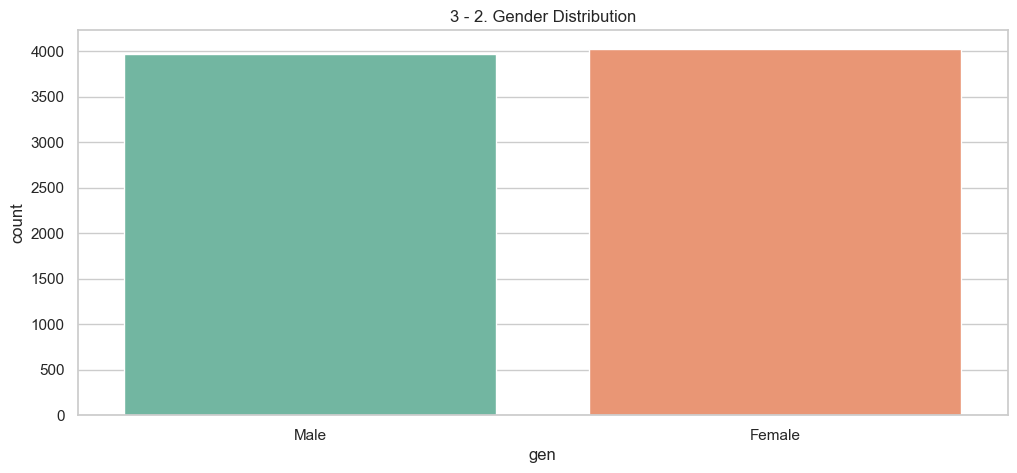

,Count
gen,
Female,4028
Male,3972


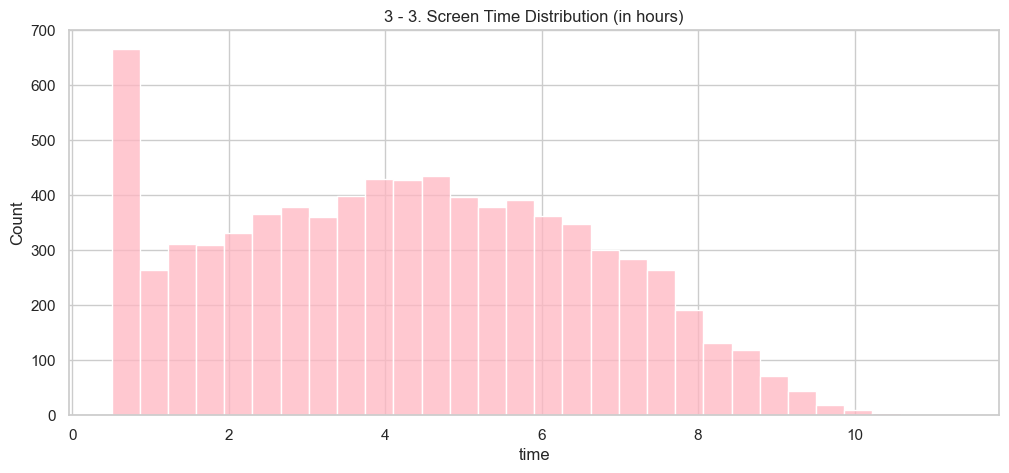

,Average,Min,Max
time,4.28,0.5,11.31


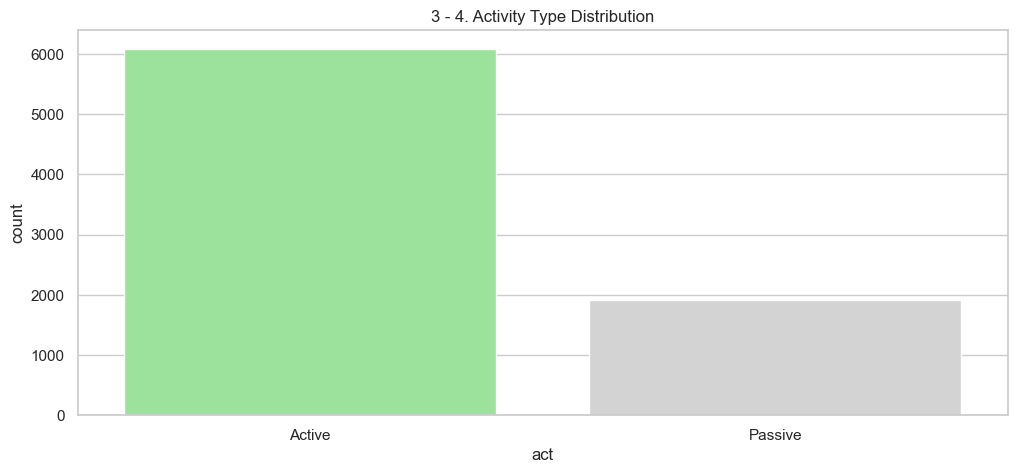

,Count
act,
Active,6091
Passive,1909


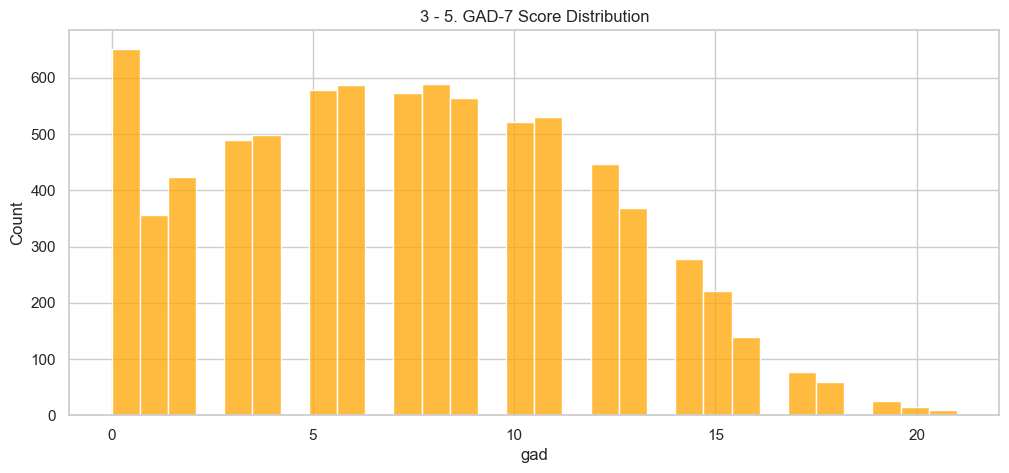

,Average,Min,Max
gad,7.35,0.0,21.0


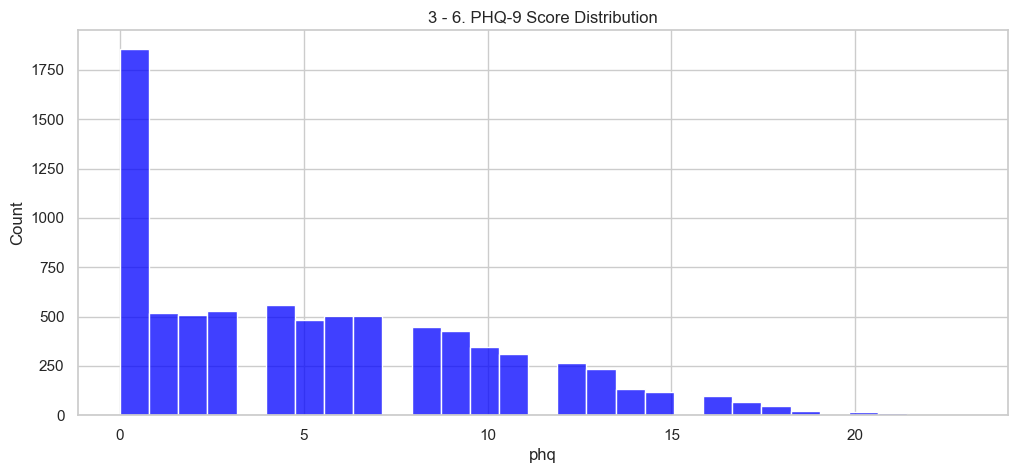

,Average,Min,Max
phq,5.38,0.0,23.0


In [68]:
sns.set_theme(style = 'whitegrid')

# 3 - 1. Age Distribution
plt.figure(figsize=(12, 5))
sns.histplot(final_df['age'], kde = False, color = 'lightblue')
plt.title('3 - 1. Age Distribution')
plt.show()

age_stats = final_df[['age']].agg(['mean', 'min', 'max']).T
age_stats.columns = ['Average', 'Min', 'Max']
display(age_stats.round(2))

# 3 - 2. Gender Distribution
plt.figure(figsize=(12, 5))
sns.countplot(x = 'gen', data = final_df, hue = 'gen', legend = False, palette = 'Set2')
plt.title('3 - 2. Gender Distribution')
plt.show()

gen_counts = final_df['gen'].value_counts().to_frame()
gen_counts.columns = ['Count']
display(gen_counts)

# 3 - 3. Screen Time Distribution
plt.figure(figsize=(12, 5))
sns.histplot(final_df['time'], kde = False, color = 'lightpink')
plt.title('3 - 3. Screen Time Distribution (in hours)')
plt.show()

time_stats = final_df[['time']].agg(['mean', 'min', 'max']).T
time_stats.columns = ['Average', 'Min', 'Max']
display(time_stats.round(2))

# 3 - 4. Activity Type Distribution
plt.figure(figsize=(12, 5))
custom_col = {'Active': 'lightgreen', 'Passive': 'Lightgray'}
sns.countplot(x = 'act', data = final_df, hue = 'act', legend = False, palette = custom_col)
plt.title('3 - 4. Activity Type Distribution')
plt.show()

act_counts = final_df['act'].value_counts().to_frame()
act_counts.columns = ['Count']
display(act_counts)

# 3 - 5. GAD-7 Score Distribution
plt.figure(figsize=(12, 5))
sns.histplot(final_df['gad'], kde = False, color = 'orange')
plt.title('3 - 5. GAD-7 Score Distribution')
plt.show()

gad_stats = final_df[['gad']].agg(['mean', 'min', 'max']).T
gad_stats.columns = ['Average', 'Min', 'Max']
display(gad_stats.round(2))

# 3 - 6. PHQ-9 Score Distribution
plt.figure(figsize=(12, 5))
sns.histplot(final_df['phq'], kde = False, color = 'blue')
plt.title('3 - 6. PHQ-9 Score Distribution')
plt.show()

phq_stats = final_df[['phq']].agg(['mean', 'min', 'max']).T
phq_stats.columns = ['Average', 'Min', 'Max']
display(phq_stats.round(2))

# 4. Relationship Analysis and Visualization

This section examines the relationship between screen time and mental health scores (GAD-7 and PHQ-9). After analyzing the relationship, the ways in which gender and activity type moderate that relationship are examined.

Overall Correlation (Screen Time and GAD-7): r = 0.63, p = 0.000


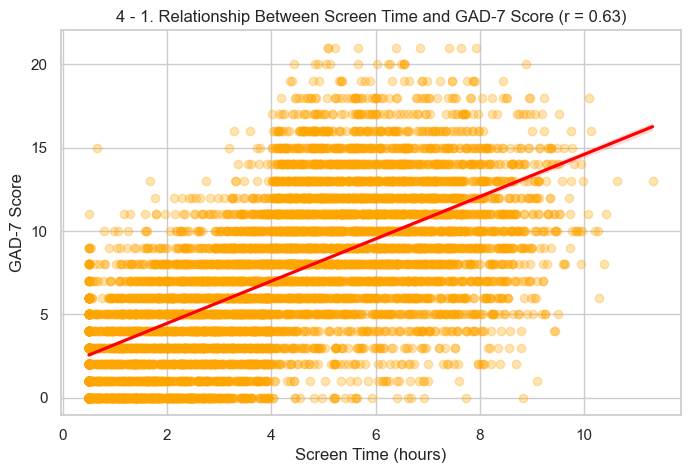

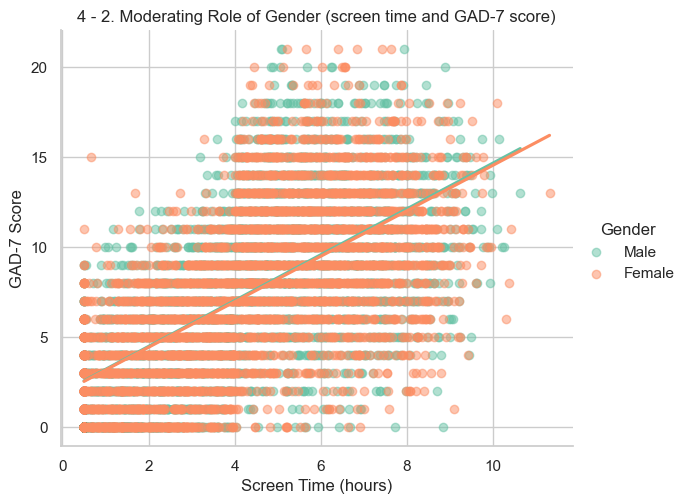

Difference by Gender:
Male r = 0.63, p = 0.000 | Female r = 0.631469, p = 0.000


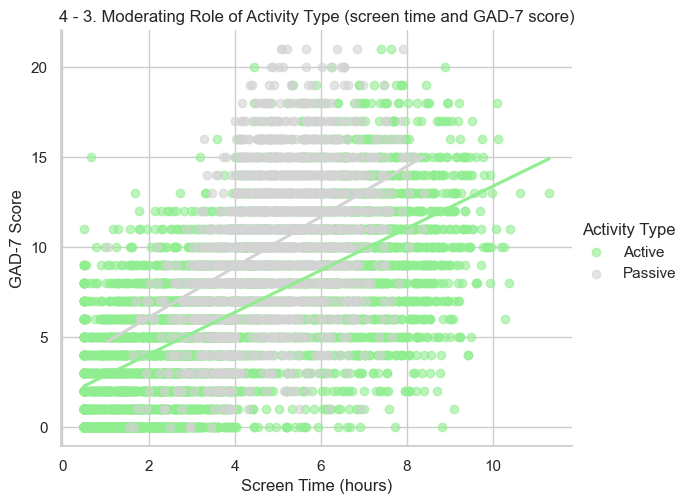

Difference by Activity Type:
Active r = 0.66, p = 0.000 | Passive r = 0.40, p = 0.000


In [48]:
# 4 - 1. Relationships between screentime and GAD-7 score
from scipy import stats

## check r and p-val for screen time & GAD-7 score
r_gad, p_gad = stats.pearsonr(final_df['time'], final_df['gad'])
print(f'Overall Correlation (Screen Time and GAD-7): r = {r_gad:.2f}, p = {p_gad:.3f}')

## visualization
plt.figure(figsize=(8, 5))
sns.regplot(x = 'time', y = 'gad', data = final_df, scatter_kws = {'alpha': 0.3, 'color':'orange'}, line_kws = {'color':'red'})
plt.title(f'4 - 1. Relationship Between Screen Time and GAD-7 Score (r = {r_gad:.2f})')
plt.xlabel('Screen Time (hours)')
plt.ylabel('GAD-7 Score')
plt.show()

# 4 - 2. Moderating role of gender (GAD-7)
r_gad_m, p_gad_m = stats.pearsonr(final_df[final_df['gen'] == 'Male']['time'], final_df[final_df['gen'] == 'Male']['gad'])
r_gad_f, p_gad_f = stats.pearsonr(final_df[final_df['gen'] == 'Female']['time'], final_df[final_df['gen'] == 'Female']['gad'])

g1 = sns.lmplot(x = 'time', y = 'gad', hue = 'gen', data = final_df, palette = 'Set2',
           ci = None, height = 5, aspect = 1.2, scatter_kws = {'alpha':0.5})

g1.legend.set_title('Gender')
plt.title('4 - 2. Moderating Role of Gender (screen time and GAD-7 score)')
plt.xlabel('Screen Time (hours)')
plt.ylabel('GAD-7 Score')
plt.show()
print(f'Difference by Gender:\nMale r = {r_gad_m:.2f}, p = {p_gad_m:.3f} | Female r = {r_gad_f:2f}, p = {p_gad_f:.3f}')

# 4 - 3. Moderating role of activity type (GAD-7)
r_gad_a, p_gad_a = stats.pearsonr(final_df[final_df['act'] == 'Active']['time'], final_df[final_df['act'] == 'Active']['gad'])
r_gad_p, p_gad_p = stats.pearsonr(final_df[final_df['act'] == 'Passive']['time'], final_df[final_df['act'] == 'Passive']['gad'])

g2 = sns.lmplot(x = 'time', y = 'gad', hue = 'act', data = final_df,
          palette = custom_col, ci = None, height = 5, aspect = 1.2, scatter_kws = {'alpha':0.6})
g2.legend.set_title('Activity Type')
plt.title('4 - 3. Moderating Role of Activity Type (screen time and GAD-7 score)')
plt.xlabel('Screen Time (hours)')
plt.ylabel('GAD-7 Score')
plt.show()
print(f'Difference by Activity Type:\nActive r = {r_gad_a:.2f}, p = {p_gad_a:.3f} | Passive r = {r_gad_p:.2f}, p = {p_gad_p:.3f}')

Overall Correlation (Screen Time and PHQ-9): r = 0.59, p = 0.000


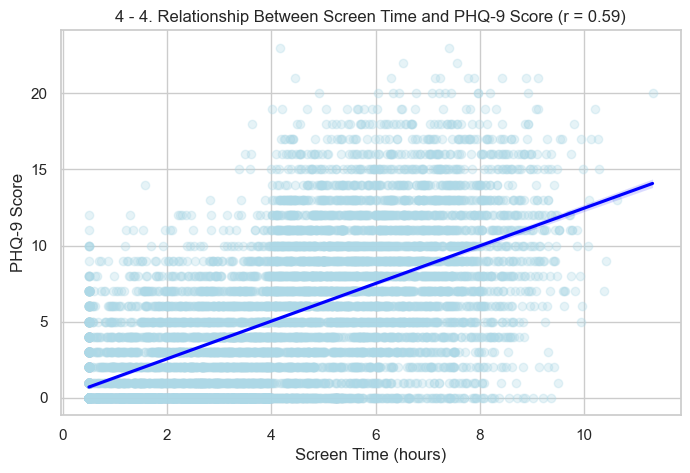

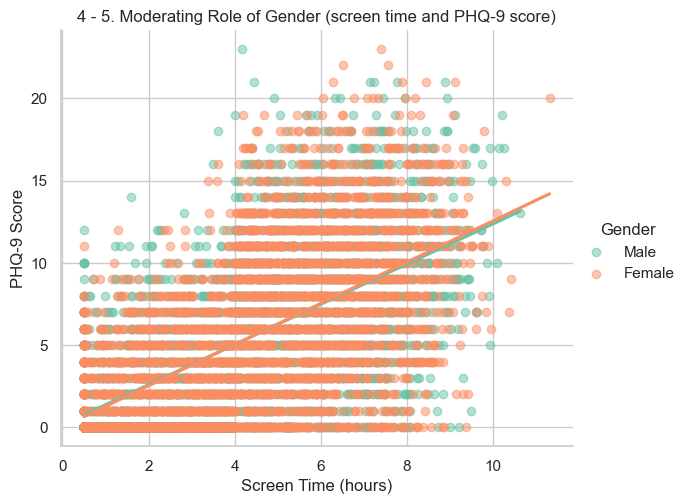

Difference by Gender:
Male r = 0.59, p = 0.000 | Female r = 0.598007, p = 0.000


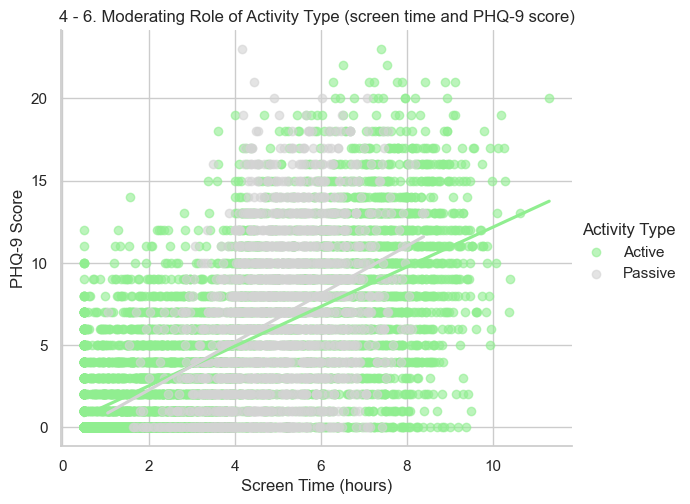

Difference by Activity Type:
Active r = 0.64, p = 0.000 | Passive r = 0.635792, p = 0.000


In [70]:
# 4 - 4. Relationship between screen time and PHQ-9 score
## check r and p-val for screen time & PHQ-9 score
r_phq, p_phq = stats.pearsonr(final_df['time'], final_df['phq'])
print(f'Overall Correlation (Screen Time and PHQ-9): r = {r_phq:.2f}, p = {p_phq:.3f}')

## visualization
plt.figure(figsize=(8, 5))
sns.regplot(x = 'time', y = 'phq', data = final_df, scatter_kws = {'alpha': 0.3, 'color':'lightblue'}, line_kws = {'color':'blue'})
plt.title(f'4 - 4. Relationship Between Screen Time and PHQ-9 Score (r = {r_phq:.2f})')
plt.xlabel('Screen Time (hours)')
plt.ylabel('PHQ-9 Score')
plt.show()

# 4 - 5. Moderating role of gender (PHQ-9)
r_phq_m, p_phq_m = stats.pearsonr(final_df[final_df['gen'] == 'Male']['time'], final_df[final_df['gen'] == 'Male']['phq'])
r_phq_f, p_phq_f = stats.pearsonr(final_df[final_df['gen'] == 'Female']['time'], final_df[final_df['gen'] == 'Female']['phq'])

g3 = sns.lmplot(x = 'time', y = 'phq', hue = 'gen', data = final_df, palette = 'Set2',
           ci = None, height = 5, aspect = 1.2, scatter_kws = {'alpha':0.5})
g3.legend.set_title('Gender')

plt.title('4 - 5. Moderating Role of Gender (screen time and PHQ-9 score)')
plt.xlabel('Screen Time (hours)')
plt.ylabel('PHQ-9 Score')
plt.show()
print(f'Difference by Gender:\nMale r = {r_phq_m:.2f}, p = {p_phq_m:.3f} | Female r = {r_phq_f:2f}, p = {p_phq_f:.3f}')

# 4 - 6. Moderating role of activity type (PHQ-9)
r_phq_a, p_phq_a = stats.pearsonr(final_df[final_df['act'] == 'Active']['time'], final_df[final_df['act'] == 'Active']['phq'])
r_phq_p, p_phq_p = stats.pearsonr(final_df[final_df['act'] == 'Passive']['time'], final_df[final_df['act'] == 'Passive']['phq'])

g4 = sns.lmplot(x = 'time', y = 'phq', hue = 'act', data = final_df,
          palette = custom_col, ci = None, height = 5, aspect = 1.2, scatter_kws = {'alpha':0.6})
g4.legend.set_title('Activity Type')

plt.title('4 - 6. Moderating Role of Activity Type (screen time and PHQ-9 score)')
plt.xlabel('Screen Time (hours)')
plt.ylabel('PHQ-9 Score')
plt.show()
print(f'Difference by Activity Type:\nActive r = {r_phq_a:.2f}, p = {p_phq_a:.3f} | Passive r = {r_phq_a:2f}, p = {p_phq_p:.3f}')

# 5. Multiple Regression Analysis

This section expands the previous analysis by performing multiple linear regression. This allows for the examination of the unique impact of screen time on mental health scores while controlling for other variables such as age and gender. The term "predictor" refers to variables included in the regression model, not to causal predictors.

--- 5 - 1. GAD-7 Regression Result ---

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.4512      0.660      5.233      0.000       2.158       4.744
time           1.1812      0.017     70.643      0.000       1.148       1.214
age            0.0493      0.034      1.448      0.148      -0.017       0.116
gen_n         -0.0307      0.076     -0.403      0.687      -0.180       0.119
act_n         -2.7236      0.091    -30.051      0.000      -2.901      -2.546
Model Accuracy (R-squared): 0.46



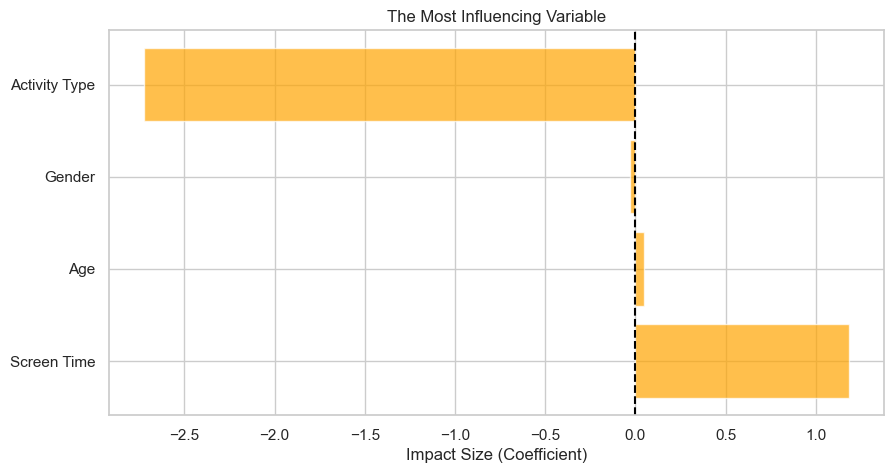

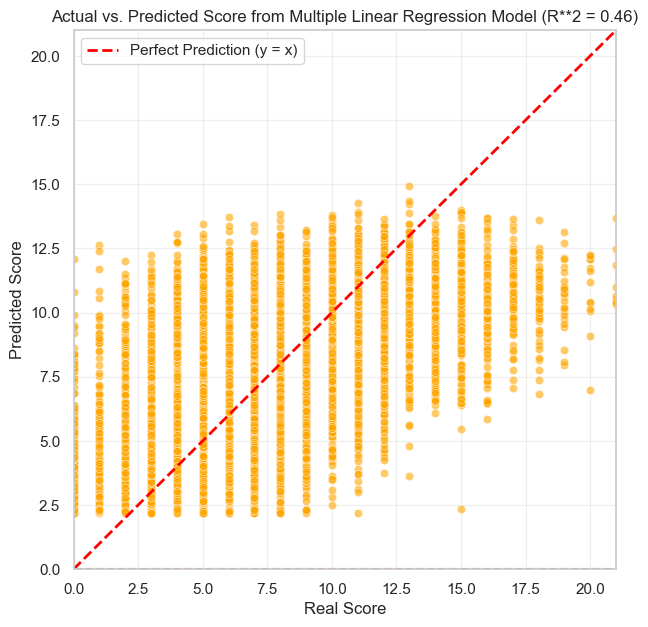

In [67]:
# 5 - 1. GAD-7 model
import statsmodels.api as sm
sns.set_theme(style = 'whitegrid')

## set predictor
X = final_df[['time', 'age', 'gen_n', 'act_n']]
X = sm.add_constant(X)

## GAD-7 Score
model_gad = sm.OLS(final_df['gad'], X).fit()
print('--- 5 - 1. GAD-7 Regression Result ---\n')
print(model_gad.summary().tables[1])
print(f'Model Accuracy (R-squared): {model_gad.rsquared:.2f}\n')

## coefficient plot visualization
plt.figure(figsize=(10, 5))
corr = model_gad.params[1:]
vars = ['Screen Time', 'Age', 'Gender', 'Activity Type']

plt.barh(vars, corr, color = 'orange', alpha = 0.7)
plt.axvline(0, color = 'black', linestyle = '--')
plt.title('The Most Influencing Variable')
plt.xlabel('Impact Size (Coefficient)')
plt.show()

## actual vs. predicted
plt.figure(figsize=(7, 7))
y_pred = model_gad.predict(X)
y_actual = final_df['gad']

sns.scatterplot(x = y_actual, y = y_pred, color = 'orange', alpha = 0.6)

line_range = [y_actual.min(), y_actual.max()]
plt.plot(line_range, line_range, color = 'red', linestyle = '--', linewidth = 2,
        label = 'Perfect Prediction (y = x)')

plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.min()], 'r--')
plt.title(f'Actual vs. Predicted Score from Multiple Linear Regression Model (R**2 = {model_gad.rsquared:.2f})')
plt.xlabel('Real Score')
plt.ylabel('Predicted Score')
plt.legend()
plt.grid(True, alpha = 0.3)
plt.xlim(line_range)
plt.ylim(line_range)

plt.show()

The multiple linear regression model explained 46% of the variation in GAD-7 scores. Screen time was a significant positive predictor of GAD-7 score, indicating that higher daily screen time was associated with higher anxiety scores after controlling for age, gender, and activity type. Activity type was also significant and showed a negative coefficient, suggesting that passive users had lower predicted GAD-7 scores than active users, depending on the coding of the variable. In contrast, age and gender were not statistically significant predictors in this model.

--- 5 - 2. PHQ-9 Regression Result ---

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.1267      0.750     -1.502      0.133      -2.597       0.343
time           1.2219      0.019     64.265      0.000       1.185       1.259
age            0.0865      0.039      2.233      0.026       0.011       0.162
gen_n          0.0074      0.087      0.085      0.932      -0.162       0.177
act_n         -0.4872      0.103     -4.727      0.000      -0.689      -0.285
Model Accuracy (R-squared): 0.35



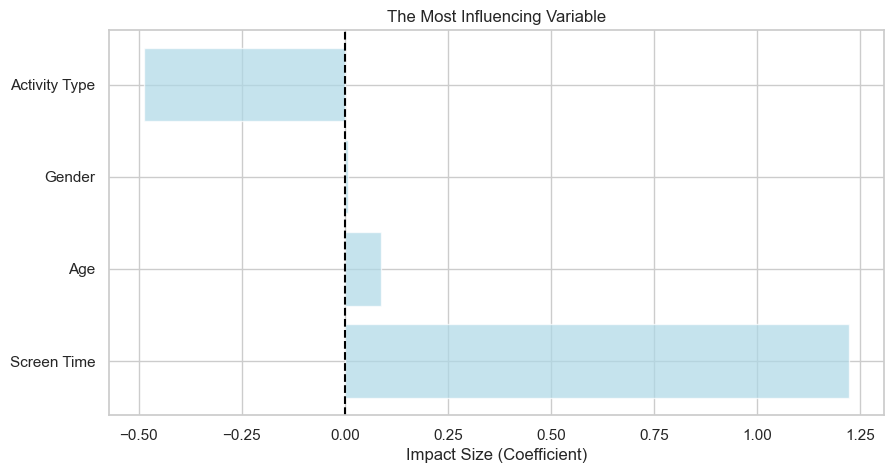

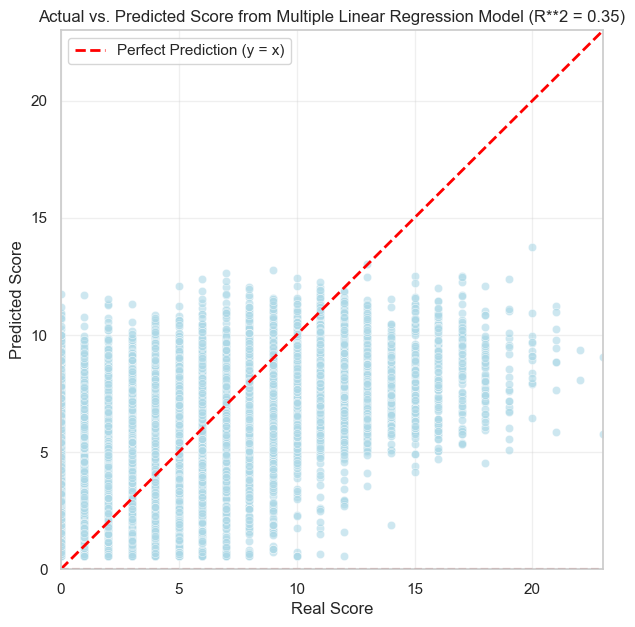

In [66]:
# 5 - 2. PHQ-9 Score model

## set predictor
X = final_df[['time', 'age', 'gen_n', 'act_n']]
X = sm.add_constant(X)

## PHQ-9
model_phq = sm.OLS(final_df['phq'], x).fit()
print('--- 5 - 2. PHQ-9 Regression Result ---\n')
print(model_phq.summary().tables[1])
print(f'Model Accuracy (R-squared): {model_phq.rsquared:.2f}\n')

## coefficient plot visualization
plt.figure(figsize=(10, 5))
corr = model_phq.params[1:]
vars = ['Screen Time', 'Age', 'Gender', 'Activity Type']

plt.barh(vars, corr, color = 'lightblue', alpha = 0.7)
plt.axvline(0, color = 'black', linestyle = '--')
plt.title('The Most Influencing Variable')
plt.xlabel('Impact Size (Coefficient)')
plt.show()

## actual vs. predicted
plt.figure(figsize=(7, 7))
y_pred = model_phq.predict(X)
y_actual = final_df['phq']

sns.scatterplot(x = y_actual, y = y_pred, color = 'lightblue', alpha = 0.6)

line_range = [y_actual.min(), y_actual.max()]
plt.plot(line_range, line_range, color = 'red', linestyle = '--', linewidth = 2,
        label = 'Perfect Prediction (y = x)')

plt.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.min()], 'r--')
plt.title(f'Actual vs. Predicted Score from Multiple Linear Regression Model (R**2 = {model_phq.rsquared:.2f})')
plt.xlabel('Real Score')
plt.ylabel('Predicted Score')
plt.legend()
plt.grid(True, alpha = 0.3)
plt.xlim(line_range)
plt.ylim(line_range)

plt.show()

The multiple linear regression model explained 35% of the variation in PHQ-9 scores. Screen time was a significant positive predictor, meaning that higher daily screen time was associated with higher depression scores after controlling for age, gender, and activity type. Age was also statistically significant, although its effect size was relatively small. Activity type was significant with a negative coefficient, suggesting that passive users had slightly lower predicted PHQ-9 scores than active users, depending on the coding of the variable. Gender was not a significant predictor.

The actual versus predicted plot shows how closely the model’s predicted scores match the real scores. The red dashed line represents perfect prediction, where actual and predicted values are equal. The points do not fall closely along this line, suggesting that the model captures the general pattern but does not perfectly predict individual mental health scores. The GAD-7 model performed better than the PHQ-9 model, with R² = .46 compared to R² = .35.

# 6. Conclusion and Limitation

**Project 1 Recap**

- Project 1 examined the relationship between daily screen time and mental health outcomes using correlation analysis and visualizations.
- The analysis found a positive relationship between screen time and both anxiety and depression scores:
  - GAD-7: r = 0.63
  - PHQ-9: r = 0.59
- Gender differences were minimal:
  - GAD-7: female r = 0.63, male r = 0.63
  - PHQ-9: female r = 0.60, male r = 0.59
- Activity type showed a clearer difference:
  - Active users: r ≈ 0.66
  - Passive users: r ≈ 0.40
- The main conclusion from Project 1 was that screen time is associated with mental health outcomes, but usage pattern may also matter.

**Project 2 Extension**

- Project 2 extends Project 1 by using Python and multiple linear regression.
- Instead of examining correlations separately, this analysis includes screen time, age, gender, and activity type in the same model.
- Two separate regression models were created:
  - GAD-7 model
  - PHQ-9 model
- This allows the analysis to examine whether screen time remains associated with anxiety and depression scores after accounting for demographic and behavioral variables.
- Coefficient plots were used to visualize the direction and size of each variable’s relationship with the outcome.
- Actual-versus-predicted plots were used to evaluate how well the regression models captured the overall patterns in the data.

**Conclusion**

- This project extended Project 1 by moving from correlation-based analysis to multiple linear regression using Python.
- Screen time remained positively associated with both GAD-7 and PHQ-9 scores after accounting for age, gender, and activity type.
- The GAD-7 model explained approximately 46% of the variation in anxiety scores.
- The PHQ-9 model explained approximately 35% of the variation in depression scores.
- Activity type was statistically significant in both models, with a stronger role in the GAD-7 model.
- Gender was not statistically significant in either model, which is consistent with the Project 1 finding that gender differences were minimal.
- Age was not statistically significant in the GAD-7 model, but it was statistically significant with a small effect size in the PHQ-9 model.
- Overall, the findings suggest that both screen time and usage pattern are important when examining the relationship between social media use and mental health outcomes.

**Limitations**

- The dataset is observational, so the results show associations rather than causal effects.
- Screen time and mental health scores were self-reported, which may introduce response bias or measurement error.
- The age range is narrow, mostly between 18 and 22 years old, so the findings may not generalize to broader populations.
- Activity type was simplified into active and passive use, which may not capture the full complexity of social media behavior.
- The regression models explained part, but not all, of the variation in mental health scores:
  - GAD-7 model: R² = 0.46
  - PHQ-9 model: R² = 0.35
- Other factors not included in the dataset, such as sleep quality, academic stress, social support, offline activity, or prior mental health conditions, may also influence anxiety and depression scores.